# 72장 · Docker Compose 네트워크와 볼륨

Compose는 여러 서비스를 하나의 설정에 적습니다. 서비스 사이의 주소, 외부에서 접속할 포트, 데이터를 보관할 볼륨은 서로 다른 설정입니다.

API와 PostgreSQL을 서로 다른 컨테이너에 두었습니다. 내 컴퓨터에서는 DB에 접속되는데 API의 localhost에서는 연결되지 않습니다. Compose 서비스 이름, 컨테이너 안팎의 포트, 데이터를 보관할 볼륨을 한 요청 경로에 맞춰 읽습니다.

실행을 확인한 커널은 Python 3.12.15입니다. 예제에 사용한 외부 패키지는 PyYAML 6.0.3입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## 서비스 이름과 내부 포트

호스트 컴퓨터에서 보는 127.0.0.1과 API 컨테이너 안에서 보는 127.0.0.1은 각자의 네트워크 공간입니다. Compose의 공통 네트워크에서는 API가 db라는 서비스 이름과 DB의 컨테이너 포트 5432로 접속합니다.

<!-- lesson-visual detail-compose -->
**같은 DB에 호스트와 API는 어디로 접속할까요?**

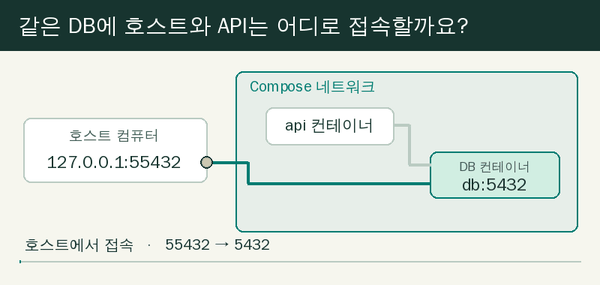

호스트에서 127.0.0.1:55432로 접속하면 공개 포트가 DB의 5432로 연결됩니다. 같은 Compose 네트워크의 API는 서비스 이름을 써서 db:5432로 곧바로 접속합니다.
<!-- /lesson-visual detail-compose -->


### API에서 보이는 주소와 호스트에서 보이는 주소

<p>Compose 네트워크의 API는 PGHOST에서 db를, PGPORT에서 5432를 읽습니다. 호스트 쪽 공개 주소는 127.0.0.1:55432입니다. 어디에서 접속하는지가 달라지면 같은 DB를 가리키는 주소도 달라집니다.</p>

<h3>Compose YAML에서 실제로 공개한 포트</h3>

<p>db의 ports에만 127.0.0.1:55432:5432가 있습니다. 호스트의 DB 클라이언트는 127.0.0.1:55432, 내부 api는 db:5432로 연결합니다. api에는 ports 항목이 없어 이 선언만으로 호스트의 8000번 포트에서 API에 접속할 수 없습니다.</p>


### 셀 01 · Compose 서비스 이름과 포트

아래는 72장 구성에서 연결·저장에 필요한 항목을 뽑은 선언입니다. PyYAML로 실제 YAML을 읽습니다.


In [1]:
import yaml
compose_text = """name: course-b1
services:
  db:
    image: pgvector/pgvector:0.8.7-pg16-trixie
    ports: ["127.0.0.1:55432:5432"]
    volumes: ["course-data:/var/lib/postgresql/data"]
  api:
    image: course-api:classroom
    environment:
      PGHOST: db
      PGPORT: "5432"
volumes:
  course-data: {}
"""
config = yaml.safe_load(compose_text)
connection = config["services"]["api"]["environment"]
print(connection["PGHOST"], connection["PGPORT"])

db 5432


db 5432는 API가 쓰는 목적지입니다. 호스트에서 DB에 접속할 때 쓰는 55432를 대신 넣으면 이 연결 경로와 맞지 않습니다.


### Compose 구성 검사에서 확인한 값

<p>docker compose config는 YAML을 해석해 정규화된 설정을 출력합니다. 여기서 DB의 target 경로를 읽은 뒤, 파일을 저장하고 다시 여는 동작은 다음 SQLite 셀에서 따로 실험합니다.</p>


### 과제 02 · 호스트 포트 매핑

db의 ports에 있는 문자열을 세 항목으로 나눠 호스트 포트만 출력하세요.


In [2]:
# 호스트 IP:호스트 포트:컨테이너 포트 순서입니다.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>port_map = config[&#x27;services&#x27;][&#x27;db&#x27;][&#x27;ports&#x27;][0]
print(port_map.split(&#x27;:&#x27;)[1])</code></pre>
<p>실행 결과</p><pre><code>55432</code></pre>
<p>55432는 호스트에서 127.0.0.1로 접속할 때 사용할 포트입니다.</p>
</details>


## 볼륨과 컨테이너 교체

선언된 볼륨은 DB의 데이터 디렉터리에 연결됩니다. 같은 컴퓨터·프로젝트의 같은 볼륨을 다시 연결해야 기존 자료를 읽을 수 있습니다. 다른 호스트에 같은 이름만 만들어도 이전 데이터가 생기는 것은 아닙니다.

**컨테이너 교체와 볼륨의 보존**　기존 장치에서 빼낸 서랍이 새 장치에 들어갑니다. 컨테이너를 바꾼 뒤 같은 데이터를 읽으려면 이전 볼륨을 다시 연결해야 합니다.

[웹 교재에서 열기](https://langchain-lecture.vercel.app/chapter72/index.html#concept-clip)


### 볼륨 이름과 컨테이너 경로

<p>course-data는 Compose에 선언한 볼륨 키이고 /var/lib/postgresql/data는 DB 컨테이너 안의 연결 위치입니다. 둘을 구분하면 컨테이너를 교체할 때 어느 저장소를 다시 연결할지 읽을 수 있습니다.</p>


### 셀 03 · Compose 구성 검증

Docker Compose가 설치된 커널에서는 실제 config 명령이 선언을 해석합니다. 이미지를 받거나 컨테이너를 띄우지 않습니다.


In [3]:
import json, shutil, subprocess
if shutil.which("docker"):
    checked = subprocess.run(["docker", "compose", "-f", "-", "config", "--format", "json"],
                             input=compose_text, text=True, capture_output=True, timeout=20)
    if checked.returncode == 0:
        normalized = json.loads(checked.stdout)
        print(normalized["services"]["db"]["volumes"][0]["target"])
    else:
        print("Compose 구성을 확인하지 못했습니다.")
else:
    print("Docker Compose CLI가 없어 선언 검사를 건너뜁니다.")

/var/lib/postgresql/data


CLI가 구성 해석에 성공하면 /var/lib/postgresql/data가 보입니다. 이 경로가 컨테이너 안에서 볼륨을 연결할 위치입니다. 실제로 재시작한 뒤 같은 문서가 남았는지는 데이터베이스에서 다시 조회해야 합니다.


## 연결을 다시 열어 저장 데이터 검증

볼륨 위에 DB가 유지된다는 말은 새 연결에서 원래 행을 다시 읽을 수 있다는 뜻입니다. 아래는 임시 파일 하나에 실제 SQLite DB를 만들고 연결을 닫았다가 다시 여는 연습입니다. Docker 컨테이너와 PostgreSQL의 재시작은 이 코드에서 일어나지 않습니다.


### 연결을 닫은 뒤에도 같은 본문을 읽는 경로

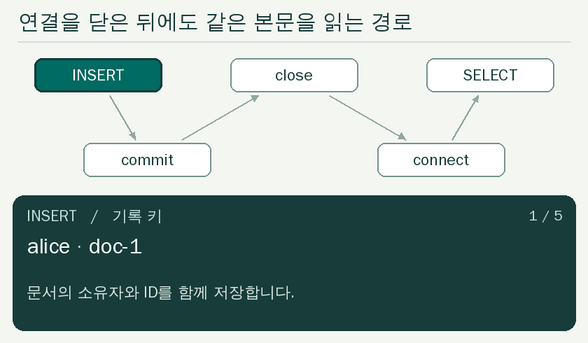

이 셀은 임시 SQLite 파일로 재연결을 실험합니다. Compose 볼륨의 실제 재생성은 별도 검증 대상입니다.


### 셀 04 · DB 재연결과 영속성 확인

행 수만 비교하면 내용이 달라져도 알아채기 어렵습니다. 같은 소유자·문서 ID로 원문을 읽고 대조하세요.

셀 03은 Compose 설정에서 연결 대상을 읽습니다. 셀 04가 다시 여는 대상은 SQLite 파일입니다. 실제 볼륨 보존을 확인하려면 같은 볼륨을 연결한 DB 컨테이너를 다시 띄우고 이전 행을 조회해야 합니다.


In [4]:
from pathlib import Path
from tempfile import TemporaryDirectory
import sqlite3

with TemporaryDirectory() as work:
    path = Path(work) / "course.db"
    db = sqlite3.connect(path)
    db.execute("CREATE TABLE docs(owner TEXT, id TEXT, body TEXT, PRIMARY KEY(owner,id))")
    db.execute("INSERT INTO docs VALUES (?,?,?)", ("alice", "doc-1", "과제함에 제출합니다."))
    db.commit()
    lookup = "SELECT body FROM docs WHERE owner=? AND id=?"
    key = ("alice", "doc-1")
    before = db.execute(lookup, key).fetchone()
    db.close()
    reopened = sqlite3.connect(path)
    after = reopened.execute(lookup, key).fetchone()
    reopened.close()
print(after[0], before == after)

과제함에 제출합니다. True


과제함 문장과 True가 함께 나옵니다. 실제 Compose 환경에서는 재시작 전후 같은 요청을 보내 이 세 값, 즉 소유자·문서 ID·원문을 비교합니다. 이전 DB 볼륨이 연결되지 않았다면 이 조회에서 원래 행을 찾을 수 없습니다. 볼륨을 확인할 때는 수업용 Compose 환경에서 한 행의 ID를 기록한 뒤 같은 볼륨을 연결해 DB 서비스를 재시작하세요. 그 ID로 다시 조회한 값을 SQLite 실습 결과와 따로 적으세요.


### 조회 조건을 고정한 재연결 검사

<p>같은 파일에서 재연결 전과 후에 같은 owner와 id로 본문을 읽습니다. before == after가 True라는 출력은 이 경로와 이 키에서 값이 유지되었다는 뜻입니다.</p>


## 돌아보기

실제 수업 환경에서 보존을 확인할 때는 과제 안내 한 건을 저장하고 문서 ID와 원문을 적어 두세요. API와 DB를 재시작한 뒤 같은 소유자·같은 ID로 조회한 원문까지 일치해야 합니다.

### 요청과 저장의 서로 다른 연결

**H1 질문 요청**　소유 대화·문서 ID가 있는 경로로 HTTP 요청합니다.

```
127.0.0.1:8000
```

**문서와 대화 확인**　컨테이너의 DB 클라이언트가 같은 B1에 연결합니다.

```
db:5432
```

**근거·A1 처리**　원문과 출처를 유지하고 결과를 만들거나 실패를 보존합니다.

```
result / error
```

**이력과 A1 저장**　저장 결과를 답변 생성 결과와 별도로 처리합니다.

```
persistence
```
